In [13]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print(X.shape)
print(data.target_names)
print(y.value_counts())
X.head(3)

(569, 30)
['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [14]:
y.head(3)

0    0
1    0
2    0
Name: target, dtype: int64

In [15]:
y = (data.target == 0).astype(int)

print(y.value_counts())
print(round(y.mean()*100, 3))

target
0    357
1    212
Name: count, dtype: int64
37.258


In [16]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [17]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [18]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
print(round(y_train.mean()*100, 3), round(y_test.mean()*100, 3))


(455, 30)
(114, 30)
(455,)
(114,)
37.363 36.842


<Axes: xlabel='target', ylabel='Count'>

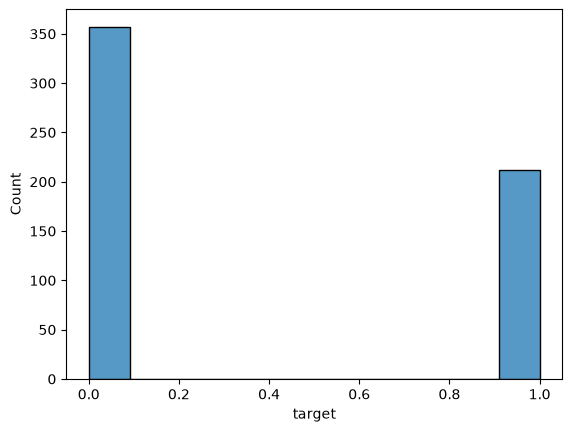

In [19]:
import matplotlib.pyplot as plt 
import seaborn as sns

sns.histplot(y)


In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logreg = Pipeline([
    ("scale",StandardScaler()),
    ("model",LogisticRegression(max_iter=10000))
])

metrics = ["accuracy","precision","recall","f1","roc_auc","average_precision"]
res = cross_validate(logreg, X_train, y_train, cv=cv, scoring=metrics)

for m in metrics:
    s = res[f"test_{m}"]
    print(m, "mean", s.mean().round(3), "std", s.std().round(3),
          "noise", (s.std() / 5**0.5).round(4))


accuracy mean 0.974 std 0.015 noise 0.0067
precision mean 0.977 std 0.028 noise 0.0125
recall mean 0.953 std 0.04 noise 0.0178
f1 mean 0.964 std 0.021 noise 0.0093
roc_auc mean 0.996 std 0.005 noise 0.0021
average_precision mean 0.995 std 0.005 noise 0.0021


[0.882 0.971 1.    0.941 0.971]
0.953


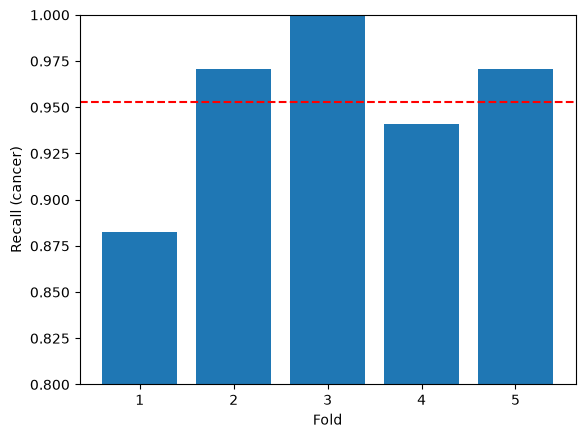

In [21]:
res = cross_validate(logreg, X_train, y_train, cv=cv, scoring=["recall"])
print(res["test_recall"].round(3))
print(res["test_recall"].mean().round(3))

plt.bar(range(1, 6), res["test_recall"])
plt.axhline(res["test_recall"].mean(), color="red", linestyle="--")
plt.ylim(0.8, 1.0)
plt.xlabel("Fold")
plt.ylabel("Recall (cancer)")
plt.show()

In [22]:
from sklearn.tree import DecisionTreeClassifier

def show(name, model):
    metrics = ["accuracy", "recall", "f1"]
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=metrics, return_train_score=True)
    print(name)
    print("  train recall:", res["train_recall"].mean().round(3))
    for m in metrics:
        s = res[f"test_{m}"]
        print(" ", m, "mean", s.mean().round(3), "std", s.std().round(3),
              "noise", (s.std() / 5**0.5).round(4))
    print("  fit time per fold (s):", res["fit_time"].mean().round(2))
    
show("Tree, no limit", DecisionTreeClassifier(random_state=42))
show("Tree, max_depth=3", DecisionTreeClassifier(max_depth=3, random_state=42))

Tree, no limit
  train recall: 1.0
  accuracy mean 0.923 std 0.033 noise 0.0146
  recall mean 0.894 std 0.061 noise 0.0271
  f1 mean 0.896 std 0.045 noise 0.02
  fit time per fold (s): 0.01
Tree, max_depth=3
  train recall: 0.938
  accuracy mean 0.921 std 0.027 noise 0.0122
  recall mean 0.859 std 0.082 noise 0.0366
  f1 mean 0.888 std 0.041 noise 0.0185
  fit time per fold (s): 0.01


In [23]:
from sklearn.ensemble import RandomForestClassifier

def show(name, model):
    metrics = ["accuracy", "recall", "f1"]
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=metrics, return_train_score=True)
    print(name)
    print("  train recall:", res["train_recall"].mean().round(3))
    for m in metrics:
        s = res[f"test_{m}"]
        print(" ", m, "mean", s.mean().round(3), "std", s.std().round(3),
              "noise", (s.std() / 5**0.5).round(4))
    print("  fit time per fold (s):", res["fit_time"].mean().round(2))

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
show("Random Forest (200 trees)", rf)

Random Forest (200 trees)
  train recall: 1.0
  accuracy mean 0.963 std 0.015 noise 0.0067
  recall mean 0.935 std 0.039 noise 0.0174
  f1 mean 0.949 std 0.021 noise 0.0094
  fit time per fold (s): 0.63


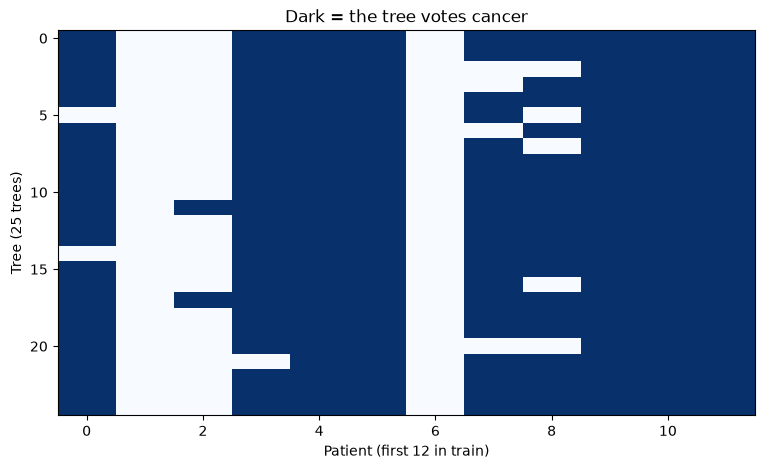

real answers: [1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1]


In [24]:
import numpy as np

small_rf = RandomForestClassifier(n_estimators=25, random_state=42)
small_rf.fit(X_train, y_train)

votes = np.array([t.predict(X_train.iloc[:12].values)
                  for t in small_rf.estimators_])

plt.figure(figsize=(9, 5))
plt.imshow(votes, aspect="auto", cmap="Blues")
plt.xlabel("Patient (first 12 in train)")
plt.ylabel("Tree (25 trees)")
plt.title("Dark = the tree votes cancer")
plt.show()
print("real answers:", y_train.iloc[:12].tolist())

                 Model  Accuracy  Recall  Recall noise      F1  Fit time (s)
0  Logistic Regression    0.9736  0.9529        0.0178  0.9640        0.0179
1      Tree (no limit)    0.9231  0.8941        0.0271  0.8962        0.0097
2        Random Forest    0.9626  0.9353        0.0174  0.9489        0.5479


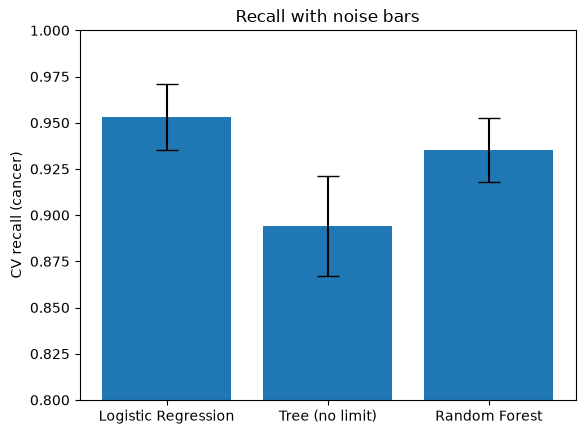

In [25]:
models = {
    "Logistic Regression": logreg,
    "Tree (no limit)": DecisionTreeClassifier(random_state=42),
    "Random Forest": rf,
}

rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=["accuracy", "recall", "f1"])
    r = res["test_recall"]
    rows.append({
        "Model": name,
        "Accuracy": res["test_accuracy"].mean(),
        "Recall": r.mean(),
        "Recall noise": r.std() / 5**0.5,
        "F1": res["test_f1"].mean(),
        "Fit time (s)": res["fit_time"].mean(),
    })

table = pd.DataFrame(rows).round(4)
print(table)

plt.bar(table["Model"], table["Recall"], yerr=table["Recall noise"], capsize=8)
plt.ylim(0.8, 1.0)
plt.ylabel("CV recall (cancer)")
plt.title("Recall with noise bars")
plt.show()

In [26]:
show("Logistic Regression", logreg)

Logistic Regression
  train recall: 0.971
  accuracy mean 0.974 std 0.015 noise 0.0067
  recall mean 0.953 std 0.04 noise 0.0178
  f1 mean 0.964 std 0.021 noise 0.0093
  fit time per fold (s): 0.02


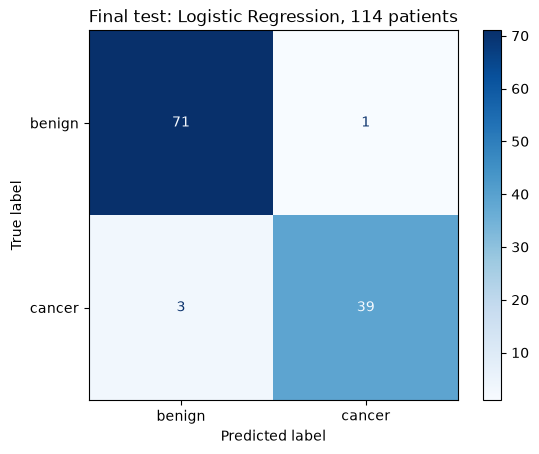

              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        72
      cancer       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [27]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

logreg.fit(X_train, y_train)
test_pred = logreg.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["benign", "cancer"], cmap="Blues")
plt.title("Final test: Logistic Regression, 114 patients")
plt.show()

print(classification_report(y_test, test_pred, target_names=["benign", "cancer"]))

In [28]:
logreg

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [29]:
import joblib
import os

os.makedirs("../models", exist_ok=True)
joblib.dump(logreg, "../models/breast_cancer_logreg.joblib")

loaded = joblib.load("../models/breast_cancer_logreg.joblib")
print((loaded.predict(X_test) == test_pred).all())

True
